# Airline Reviews: Aspect-Based Sentiment Analysis

Sentence-level airline reviews (Aeroflot, China Southern, Qatar Airways, Turkish Airlines). Each sentence is labelled with the **aspect** it talks about (staff, luggage, meals, ...) and a **sentiment score**.

**Notebook outline**

1. Setup and configuration
2. Load the raw CSV
3. Repair malformed rows
4. Type conversion and data-quality checks
5. Understand the label scale
6. Clean the review text
7. Reshape to one row per aspect mention
8. Sentiment by aspect
9. Airline comparison (review level)
10. Most common words
11. Sentiment classifier
12. Error analysis
13. Save a results summary

## 1. Setup and configuration

Everything that depends on an assumption lives in this cell, so you can change it in one place.

**Label scale (inferred, not documented).** Aspect values run from 0 to 5, where 0 means *the aspect is not mentioned*. Reading example sentences (section 5) suggests:

| Score | Reading |
|---|---|
| 1 | very negative |
| 2 | negative |
| 3 | mildly negative (a problem or complaint) |
| 4 | neutral / mixed (for example "Not amazing though.") |
| 5 | positive |



In [ ]:
import csv, io, os, re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

pd.set_option("display.max_columns", None)

DATA_PATH = r"C:\Users\adity\Downloads\Airline_Reviews.csv"     
os.makedirs("images", exist_ok=True)
os.makedirs("results", exist_ok=True)

NEGATIVE_MAX = 3          
NEUTRAL_SCORES = {4}      

def to_sentiment(score):
    if score <= NEGATIVE_MAX:
        return "Negative"
    if score in NEUTRAL_SCORES:
        return "Neutral/Mixed"
    return "Positive"

## 2. Load the raw CSV

The raw file has 14 columns: airline, review number, sentence number, the sentence, and 10 aspect columns. The header of the last column ends with a stray `;;`, which is cleaned up here.

In [2]:
raw = pd.read_csv(DATA_PATH)
raw.columns = raw.columns.str.replace(";", "", regex=False).str.strip()

print("Rows:", raw.shape[0], "| Columns:", raw.shape[1])
raw.info()
raw.head()

Rows: 736 | Columns: 14
<class 'pandas.DataFrame'>
RangeIndex: 736 entries, 0 to 735
Data columns (total 14 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Airline                              736 non-null    str    
 1   Review No                            508 non-null    str    
 2   Sentence No                          508 non-null    float64
 3   Sentence                             508 non-null    str    
 4   Luggage                              508 non-null    float64
 5   Staff                                508 non-null    float64
 6   In-flight/on-board service           508 non-null    float64
 7   Airline as a whole                   508 non-null    float64
 8   Service before and after the flight  508 non-null    float64
 9   Flight in general                    508 non-null    float64
 10  Comfort while waiting                508 non-null    str    
 11  Meals              

,Airline,Review No,Sentence No,Sentence,Luggage,Staff,In-flight/on-board service,Airline as a whole,Service before and after the flight,Flight in general,Comfort while waiting,Meals,Cabin,Transportation to the plane
0,Qatar Airways,1,1.0,Qatar Airways lost my luggage and refused to d...,2.0,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0;;
1,"Qatar Airways,1,2,""Terrible staff, no professi...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Qatar Airways,1,3.0,They make it seem like it was your fault someh...,0.0,2.0,0.0,0.0,2.0,0.0,0,0,0.0,0;;
3,"Qatar Airways,1,4,""Qatar Airways: """"Why don't ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Qatar Airways,1,5.0,How dare you?,0.0,2.0,0.0,0.0,2.0,0.0,0,0,0.0,0;;


## 3. Repair malformed rows

Some rows were written with the **whole line inside the `Airline` field** (extra quotes around the line), so every other column is empty. They are recognisable by a comma inside `Airline`. Each one is re-parsed with Python's `csv` module and merged back.

In [ ]:
bad = raw["Airline"].str.contains(",", na=False)
print("Malformed rows:", int(bad.sum()))

if bad.any():
    fixed = pd.DataFrame([next(csv.reader(io.StringIO(line))) for line in raw.loc[bad, "Airline"]])
    assert fixed.shape[1] == raw.shape[1], f"field mismatch: {fixed.shape[1]} vs {raw.shape[1]}"
    fixed.columns = raw.columns
    df = pd.concat([raw.loc[~bad], fixed], ignore_index=True)
else:
    df = raw.copy()

print("Rows after repair:", df.shape[0])

Malformed rows: 232
Rows after repair: 736


## 4. Type conversion and data-quality checks

- Strip stray quotes and spaces from `Airline`.
- Remove the `;` characters and convert the aspect columns to numbers.
- A few rows have a missing label; they are set to 0 (no aspect), because the sentence text is present.
- Sort so that sentences of a review are in order.

In [4]:
df["Airline"] = df["Airline"].str.strip(' "')
aspects = list(df.columns[4:])

for col in aspects:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(";", "", regex=False), errors="coerce")
for col in ["Review No", "Sentence No"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

key_cols = ["Review No", "Sentence No", "Sentence"]
dropped = int(df[key_cols].isnull().any(axis=1).sum())
df = df.dropna(subset=key_cols)
df[["Review No", "Sentence No"]] = df[["Review No", "Sentence No"]].astype(int)
print("Rows dropped for missing key fields:", dropped)

print("Missing aspect labels per column:")
print(df[aspects].isnull().sum().to_dict())
df[aspects] = df[aspects].fillna(0).astype(int)

df = df.sort_values(["Airline", "Review No", "Sentence No"]).reset_index(drop=True)
df["pos_in_review"] = df.groupby(["Airline", "Review No"]).cumcount() + 1

Rows dropped for missing key fields: 0
Missing aspect labels per column:
{'Luggage': 4, 'Staff': 4, 'In-flight/on-board service': 4, 'Airline as a whole': 4, 'Service before and after the flight': 4, 'Flight in general': 4, 'Comfort while waiting': 4, 'Meals': 4, 'Cabin': 4, 'Transportation to the plane': 4}


In [5]:
print("Missing values in key columns:")
print(df[["Airline", "Review No", "Sentence No", "Sentence"]].isnull().sum().to_dict())
print("\nDuplicate sentences:", int(df["Sentence"].duplicated().sum()))

reviews_per_airline = df.groupby("Airline")["Review No"].nunique()
print("\nReviews per airline:")
print(reviews_per_airline)

print("\nSentences per airline:")
print(df["Airline"].value_counts())

print("\nLongest reviews (sentences):")
print(df.groupby(["Airline", "Review No"]).size().sort_values(ascending=False).head(5))

Missing values in key columns:
{'Airline': 0, 'Review No': 0, 'Sentence No': 0, 'Sentence': 0}

Duplicate sentences: 45

Reviews per airline:
Airline
Aeroflot              25
China Southern ALs    25
Qatar Airways         25
Turkish ALs           25
Name: Review No, dtype: int64

Sentences per airline:
Airline
Turkish ALs           321
Qatar Airways         222
China Southern ALs    109
Aeroflot               84
Name: count, dtype: int64

Longest reviews (sentences):
Airline        Review No
Turkish ALs    86           102
Qatar Airways  23            40
Turkish ALs    77            25
Qatar Airways  13            19
Turkish ALs    83            19
dtype: int64


**What to notice:** every airline has the same number of reviews, but the sentence counts are very uneven because a few reviews are very long. A single long review can dominate a sentence-level comparison, which is why the airline comparison in section 9 counts each *review* once.

## 5. Understand the label scale

The dataset does not explain what the scores mean, so print example sentences for each value. Read them and check that the mapping in section 1 matches.

In [6]:
for score in range(1, 6):
    rows = []
    for col in aspects:
        rows += df.loc[df[col] == score, "Sentence"].tolist()
    print(f"\nscore = {score}  ({len(rows)} aspect labels)")
    rng = np.random.default_rng(0)
    for s in rng.permutation(rows)[:6]:
        print("   -", s[:130])


score = 1  (526 aspect labels)
   - I informed her that the passenger seated in front was not wearing a mask.
   - I lost a lot of money and time because of this.
   - Most dishonest and unhelpful airline in the world.
   - My experience with 8 months old baby was horrible never again.
   - I arrived at the check-in desk 1 hour 20 minutes before my flight and the manager barked at me that they closed the registration h
   - Really not a good experience on board at all and I will avoid flying this airline if I can avoid it.

score = 2  (75 aspect labels)
   - Terrible staff, no professionalism at all, no one answers emails and it's impossible to solve anything.
   - Whilst this was a B787 I think it was an older one where the cabin had not been upgraded I found the seat reasonably comfortable i
   - Hope I travel with them again.
   - Only when it was one hour before the landing the temperature in the salon became OK, but there was no time to sleep anymore.
   - Hepa filters, air chang

## 6. Clean the review text

Steps: expand `n't` to `not`, keep letters only, lowercase, remove stopwords, lemmatize, and drop one-letter leftovers. **Negation words are kept** (*no, not, nor, never*), because they flip the meaning of a sentence.

The raw `Sentence` column is kept as well; section 11 shows that the raw text works slightly better for the classifier.

In [ ]:
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

KEEP = {"not", "no", "nor", "never"}
STOP = set(stopwords.words("english")) - KEEP  
lemma = WordNetLemmatizer()

def clean(text):
    text = str(text).lower()
    text = re.sub(r"n['’]t\b", " not", text)       
    text = re.sub(r"[^a-z]", " ", text)
    words = [w for w in text.split() if len(w) > 1 and w not in STOP]
    return " ".join(lemma.lemmatize(w) for w in words)

df["corpus"] = df["Sentence"].apply(clean)
df[["Sentence", "corpus"]].head()

,Sentence,corpus
0,Thanks to Aeroflot for comfortable flight.,thanks aeroflot comfortable flight
1,Always choose this company and they never disa...,always choose company never disapoint
2,Like Aeroflot for it’s comfort even for econom...,like aeroflot comfort even economy class leg s...
3,And in Moscow in cold period you always leave ...,moscow cold period always leave plane straight...
4,Flight to and back from Dubai was perfect.,flight back dubai perfect


## 7. Reshape to one row per aspect mention

A sentence can talk about several aspects. The long table has **one row per (sentence, aspect)** where the aspect is mentioned (score above 0), with the sentiment group from section 1.

In [8]:
long_df = (
    df.melt(id_vars=["Airline", "Review No", "Sentence", "corpus"],
            value_vars=aspects, var_name="aspect", value_name="score")
      .query("score > 0")
      .reset_index(drop=True)
)
long_df["sentiment"] = long_df["score"].map(to_sentiment)

print("Aspect mentions:", len(long_df), "| from", long_df["Sentence"].nunique(), "sentences")
counts = long_df.groupby(["aspect", "sentiment"]).size().unstack(fill_value=0)
counts

Aspect mentions: 945 | from 610 sentences


sentiment,Negative,Neutral/Mixed,Positive
aspect,,,
Airline as a whole,83,2,33
Cabin,7,0,20
Comfort while waiting,13,1,4
Flight in general,20,5,44
In-flight/on-board service,105,3,57
Luggage,38,0,6
Meals,21,2,20
Service before and after the flight,273,5,54
Staff,84,0,38


## 8. Sentiment by aspect

Percentages are used instead of raw counts, so frequently mentioned aspects do not look more negative just because they have more rows. Aspects with fewer than 20 mentions are left out of the chart, and each bar is labelled with its sample size.

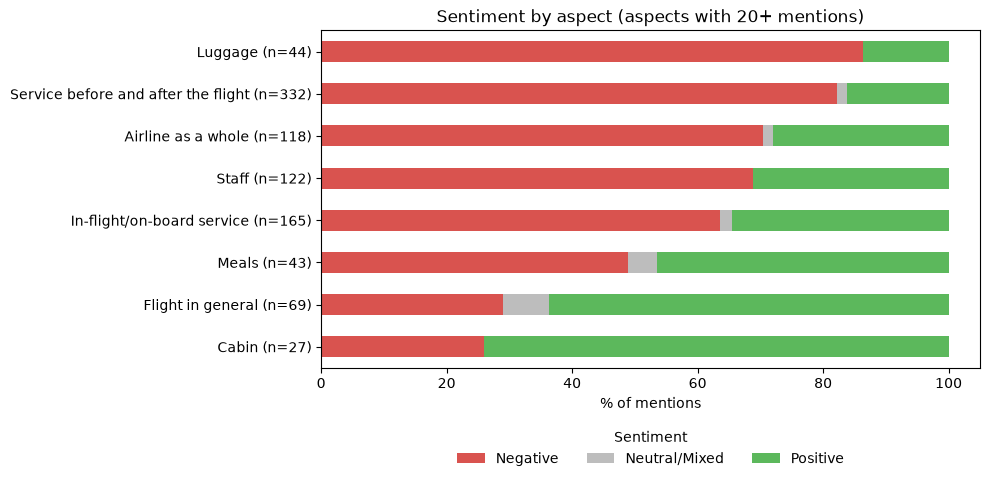

In [9]:
ct = counts.copy()
ct["total"] = ct.sum(axis=1)
cols = [c for c in ["Negative", "Neutral/Mixed", "Positive"] if c in ct.columns]
pct = ct[cols].div(ct["total"], axis=0) * 100
pct = pct[ct["total"] >= 20].sort_values("Negative")
pct.index = [f"{a} (n={int(ct.loc[a, 'total'])})" for a in pct.index]

colors = {"Negative": "#d9534f", "Neutral/Mixed": "#bdbdbd", "Positive": "#5cb85c"}
ax = pct.plot(kind="barh", stacked=True, figsize=(10, 5), color=[colors[c] for c in pct.columns])
ax.set_xlabel("% of mentions")
ax.set_ylabel("")
ax.set_title("Sentiment by aspect (aspects with 20+ mentions)")
ax.legend(title="Sentiment", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig("images/sentiment_by_aspect.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Airline comparison (review level)

Each review counts **once** per aspect: the table shows the share of an airline's reviews that contain at least one negative mention of that aspect. Only aspects with 40 or more mentions are compared.

With around 25 reviews per airline, one review is about 4 percentage points, so small gaps are not meaningful. The second block checks how much the single longest review matters.

In [10]:
main_aspects = counts.sum(axis=1)[lambda s: s >= 40].index.tolist()

per_review = (
    long_df[long_df["aspect"].isin(main_aspects)]
    .assign(neg=lambda d: d["sentiment"].eq("Negative"))
    .groupby(["Airline", "Review No", "aspect"])["neg"].any()
    .reset_index()
)
neg_reviews = per_review.groupby(["aspect", "Airline"])["neg"].sum().unstack(fill_value=0)
neg_share = (neg_reviews / reviews_per_airline * 100).round(0)

print("% of each airline's reviews with a negative mention")
neg_share

% of each airline's reviews with a negative mention


Airline,Aeroflot,China Southern ALs,Qatar Airways,Turkish ALs
aspect,,,,
Airline as a whole,0.0,32.0,64.0,80.0
Flight in general,4.0,4.0,8.0,20.0
In-flight/on-board service,12.0,24.0,24.0,36.0
Luggage,0.0,4.0,24.0,16.0
Meals,4.0,12.0,8.0,20.0
Service before and after the flight,16.0,60.0,68.0,84.0
Staff,4.0,16.0,36.0,56.0


In [11]:
sizes = df.groupby(["Airline", "Review No"]).size()
(top_airline, top_review), top_n = sizes.idxmax(), sizes.max()
print(f"Longest review: {top_airline}, review {top_review}, {top_n} sentences "
      f"({top_n / (df['Airline'] == top_airline).sum():.0%} of that airline's sentences)")

without = long_df[~((long_df["Airline"] == top_airline) & (long_df["Review No"] == top_review))]
robust = without.groupby(["Airline", "sentiment"]).size().unstack(fill_value=0)
robust["negative_%"] = (robust.get("Negative", 0) / robust.sum(axis=1) * 100).round(0)
print("\nAll aspect mentions without that review:")
robust

Longest review: Turkish ALs, review 86, 102 sentences (32% of that airline's sentences)

All aspect mentions without that review:


sentiment,Negative,Neutral/Mixed,Positive,negative_%
Airline,,,,
Aeroflot,18,3,105,14.0
China Southern ALs,81,5,57,57.0
Qatar Airways,170,8,66,70.0
Turkish ALs,268,2,12,95.0


## 10. Most common words

Which words appear most in negative and positive mentions? Airline names and filler words are removed.

In [12]:
generic = {"flight", "airline", "plane", "aeroflot", "turkish", "qatar", "china", "southern",
           "airway", "airlines", "one", "get", "got", "would", "also", "could", "us"}

def top_words(sentiment, n=15):
    words = Counter()
    for text in long_df.loc[long_df["sentiment"] == sentiment, "corpus"]:
        words.update(text.split())
    return [(w, c) for w, c in words.most_common(80) if w not in generic][:n]

print("Negative:", top_words("Negative"))
print("Positive:", top_words("Positive"))

Negative: [('not', 155), ('no', 99), ('passenger', 89), ('time', 59), ('service', 57), ('customer', 56), ('airport', 53), ('mask', 50), ('u', 47), ('hour', 45), ('rude', 38), ('ticket', 36), ('crew', 36), ('without', 34), ('made', 33)]
Positive: [('good', 57), ('service', 52), ('food', 27), ('staff', 27), ('not', 26), ('mask', 26), ('time', 24), ('everything', 22), ('board', 20), ('comfortable', 19), ('u', 17), ('business', 16), ('passenger', 16), ('meal', 16), ('friendly', 15)]


## 11. Sentiment classifier

Task: predict whether an aspect mention is **Negative** or **Positive** from its sentence.

- Neutral/Mixed is dropped (too few examples), as are sentences that carry contradictory labels for different aspects.
- Model: TF-IDF (1-2-grams) + logistic regression with balanced class weights.
- Evaluation: 5-fold **`GroupKFold` grouped by review**, so sentences from one review never appear in both train and test.
- Three input versions are compared, and the **majority-class baseline** is shown for reference.

In [13]:
d = long_df[long_df["sentiment"] != "Neutral/Mixed"].drop_duplicates(["Sentence", "sentiment"])
d = d[d.groupby("Sentence")["sentiment"].transform("nunique") == 1].reset_index(drop=True)

counts_y = d["sentiment"].value_counts()
baseline = counts_y.max() / counts_y.sum()
print("Labelled sentences:", len(d), counts_y.to_dict())
print(f"Majority-class baseline accuracy: {baseline:.3f}")

model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)
cv = GroupKFold(n_splits=5)

variants = {
    "cleaned corpus":        d["corpus"],
    "raw sentence":          d["Sentence"],
    "aspect + raw sentence": d["aspect"] + " " + d["Sentence"],
}
predictions, scores = {}, []
for name, X in variants.items():
    p = cross_val_predict(model, X, d["sentiment"], groups=d["Review No"], cv=cv)
    predictions[name] = p
    scores.append({"input": name,
                   "accuracy": round(float((p == d["sentiment"]).mean()), 3),
                   "macro_f1": round(float(f1_score(d["sentiment"], p, average="macro")), 3)})

results = pd.DataFrame(scores)
results

Labelled sentences: 596 {'Negative': 430, 'Positive': 166}
Majority-class baseline accuracy: 0.721


,input,accuracy,macro_f1
0,cleaned corpus,0.802,0.744
1,raw sentence,0.810,0.756
2,aspect + raw sentence,0.795,0.744


Best input: raw sentence 

              precision    recall  f1-score   support

    Negative       0.85      0.89      0.87       430
    Positive       0.68      0.61      0.64       166

    accuracy                           0.81       596
   macro avg       0.77      0.75      0.76       596
weighted avg       0.81      0.81      0.81       596



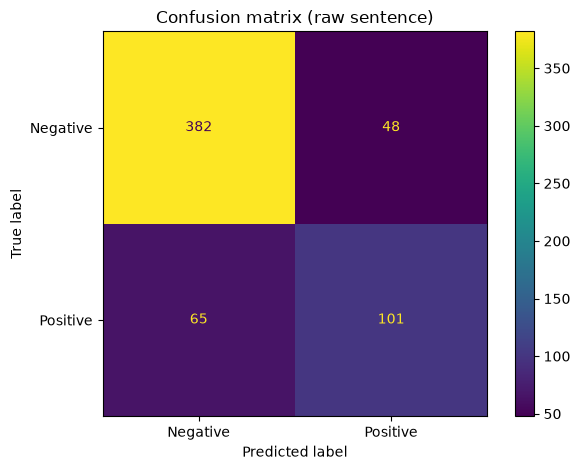

In [14]:
best = results.sort_values("macro_f1", ascending=False).iloc[0]["input"]
pred = predictions[best]
print("Best input:", best, "\n")
print(classification_report(d["sentiment"], pred))

ConfusionMatrixDisplay.from_predictions(d["sentiment"], pred)
plt.title(f"Confusion matrix ({best})")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=200)
plt.show()

## 12. Error analysis

Reading the mistakes shows whether they come from the model or from the labels.

In [15]:
errors = d.assign(pred=pred)
errors = errors[errors["sentiment"] != errors["pred"]]

for true_label in ["Positive", "Negative"]:
    print(f"\nTRUE {true_label}, predicted the other class:")
    for _, row in errors[errors["sentiment"] == true_label].head(10).iterrows():
        print(f"  [{row['aspect']}] {row['Sentence'][:140]}")


TRUE Positive, predicted the other class:
  [Luggage] I could see that they were very friendly and helped many people store their luggage.
  [Luggage] Our car drew up outside the Business Class area and a porter immediately took our bags.
  [Luggage] I called before purchasing the ticket and THY told me that since its same day international flight my luggages will same as international tr
  [Luggage] Before the outside of the box was delivered in Dubai, it was wrapped very tightly with a stretch like a shell by the authorities at Dubai Ai
  [Staff] The cabin crew members were fantastic on this 2-hour 15-minute non-stop flight from Wuxi (WUX) to Guangzhou (CAN).
  [Staff] Even the hard pressed flight attendants interspersed helping myself and other passengers in this regard while at the same time busy with the
  [Staff] My sincere thanks to them.
  [Staff] Comfort in Premium Economy was not to bad at all, and the flight staff where wonderful.
  [Staff] I would especially like to mentio

## 13. Save a results summary

Writes the tables from this run to `results/summary.md`

In [ ]:
def md_table(frame):
    frame = frame.reset_index()
    header = "| " + " | ".join(str(c) for c in frame.columns) + " |"
    divider = "|" + "---|" * len(frame.columns)
    rows = ["| " + " | ".join(str(v) for v in r) + " |" for r in frame.itertuples(index=False)]
    return "\n".join([header, divider] + rows)

shares = neg_share.copy()
shares.columns.name = None

summary = f"""# Results summary 

Label mapping: scores 1-{NEGATIVE_MAX} Negative, {sorted(NEUTRAL_SCORES)} Neutral/Mixed, higher Positive.

- Reviews: {df.groupby(['Airline', 'Review No']).ngroups}, sentences: {len(df)}, aspect mentions: {len(long_df)}
- Classifier sentences: {len(d)} ({counts_y.to_dict()}), majority baseline accuracy: {baseline:.3f}

## Sentiment by aspect (mentions)

{md_table(counts)}

## Share of reviews with a negative mention

{md_table(shares)}

## Classifier

{md_table(results)}

Best input: {best}

```
{classification_report(d['sentiment'], pred)}
```
"""
with open("results/summary.md", "w", encoding="utf-8") as f:
    f.write(summary)
print("Saved results/summary.md")

Saved results/summary.md


# Results summary

Label mapping: scores 1-3 Negative, [4] Neutral/Mixed, higher Positive.

- Reviews: 100, sentences: 736, aspect mentions: 945
- Classifier sentences: 596 ({'Negative': 430, 'Positive': 166}), majority baseline accuracy: 0.721

## Sentiment by aspect (mentions)

| aspect | Negative | Neutral/Mixed | Positive |
|---|---|---|---|
| Airline as a whole | 83 | 2 | 33 |
| Cabin | 7 | 0 | 20 |
| Comfort while waiting | 13 | 1 | 4 |
| Flight in general | 20 | 5 | 44 |
| In-flight/on-board service | 105 | 3 | 57 |
| Luggage | 38 | 0 | 6 |
| Meals | 21 | 2 | 20 |
| Service before and after the flight | 273 | 5 | 54 |
| Staff | 84 | 0 | 38 |
| Transportation to the plane | 5 | 0 | 2 |

## Share of reviews with a negative mention

| aspect | Aeroflot | China Southern ALs | Qatar Airways | Turkish ALs |
|---|---|---|---|---|
| Airline as a whole | 0.0 | 32.0 | 64.0 | 80.0 |
| Flight in general | 4.0 | 4.0 | 8.0 | 20.0 |
| In-flight/on-board service | 12.0 | 24.0 | 24.0 | 36.0 |
| Luggage | 0.0 | 4.0 | 24.0 | 16.0 |
| Meals | 4.0 | 12.0 | 8.0 | 20.0 |
| Service before and after the flight | 16.0 | 60.0 | 68.0 | 84.0 |
| Staff | 4.0 | 16.0 | 36.0 | 56.0 |

## Classifier

| index | input | accuracy | macro_f1 |
|---|---|---|---|
| 0 | cleaned corpus | 0.802 | 0.744 |
| 1 | raw sentence | 0.81 | 0.756 |
| 2 | aspect + raw sentence | 0.795 | 0.744 |

Best input: raw sentence

```
              precision    recall  f1-score   support

    Negative       0.85      0.89      0.87       430
    Positive       0.68      0.61      0.64       166

    accuracy                           0.81       596
   macro avg       0.77      0.75      0.76       596
weighted avg       0.81      0.81      0.81       596

```
